In [105]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
%matplotlib inline

In [106]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

In [107]:
x,y=make_classification(n_classes=2,n_clusters_per_class=1,n_features=10,n_redundant=0,weights=[0.99],random_state=10,n_samples=10000)

In [108]:
Counter(y)

Counter({np.int64(0): 9844, np.int64(1): 156})

In [109]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=42)

In [110]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(7000, 10)
(3000, 10)
(7000,)
(3000,)


In [111]:
## create a dummy model with default 0 as output
dummy_model_prob=[0 for _ in range(len(y_test))]
Counter(dummy_model_prob)

Counter({0: 3000})

In [112]:
#apply normal logistic regression
model=LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [113]:
##making prediction based on probabilities
y_prob=model.predict_proba(x_test)

In [114]:
print(y_prob)

[[9.97473731e-01 2.52626943e-03]
 [9.97059852e-01 2.94014760e-03]
 [9.97711918e-01 2.28808170e-03]
 ...
 [9.99423759e-01 5.76241286e-04]
 [9.98226532e-01 1.77346760e-03]
 [9.87320206e-01 1.26797943e-02]]


In [115]:
##focus on prob of 1
model_prob=y_prob[:,1]

In [116]:
##calculate scores
dummy_model_score=roc_auc_score(y_test,dummy_model_prob)
og_model_prob=roc_auc_score(y_test,model_prob)
print("The accuracy of dummy model is:",dummy_model_score)
print("The accuracy of Real Model is:",og_model_prob)

The accuracy of dummy model is: 0.5
The accuracy of Real Model is: 0.8212949152542371


In [117]:
##Calculate ROC AUC CURVE
dummy_fpr,dummy_tpr, _ =roc_curve(y_test,dummy_model_prob)
model_fpr,model_tpr,thresholds =roc_curve(y_test,model_prob)

In [118]:
thresholds

array([           inf, 9.84929279e-01, 4.54302368e-01, 4.47259575e-01,
       3.20631299e-01, 3.02913286e-01, 2.74604047e-01, 2.74538623e-01,
       2.52611375e-01, 2.46080672e-01, 2.42033703e-01, 2.33161063e-01,
       2.27816608e-01, 2.14608321e-01, 1.99412421e-01, 1.50213255e-01,
       1.41721193e-01, 1.14069826e-01, 1.13589562e-01, 6.46688234e-02,
       6.44205439e-02, 4.79146029e-02, 4.78599769e-02, 4.70111463e-02,
       4.65964426e-02, 4.55351964e-02, 4.53274480e-02, 3.87254504e-02,
       3.86504952e-02, 3.48518039e-02, 3.48166771e-02, 2.75166177e-02,
       2.75021473e-02, 2.58499234e-02, 2.57516706e-02, 2.47506988e-02,
       2.46486111e-02, 1.99368145e-02, 1.98686562e-02, 1.85005839e-02,
       1.84833767e-02, 1.32989059e-02, 1.32877811e-02, 8.90613281e-03,
       8.87260222e-03, 8.54102558e-03, 8.53562023e-03, 6.58877515e-03,
       6.58617437e-03, 5.78124907e-03, 5.77067886e-03, 3.35671620e-03,
       3.34667881e-03, 3.27221024e-03, 3.26654101e-03, 3.09385643e-03,
      

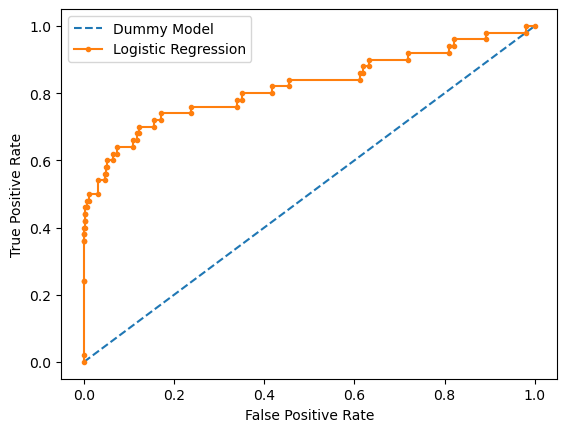

In [119]:
##plot the roc curve for the model
plt.plot(dummy_fpr,dummy_tpr,linestyle='--',label="Dummy Model")
plt.plot(model_fpr,model_tpr,marker='.',label='Logistic Regression')
#axis lables
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
#show legend
plt.legend()
#show plot
plt.show()

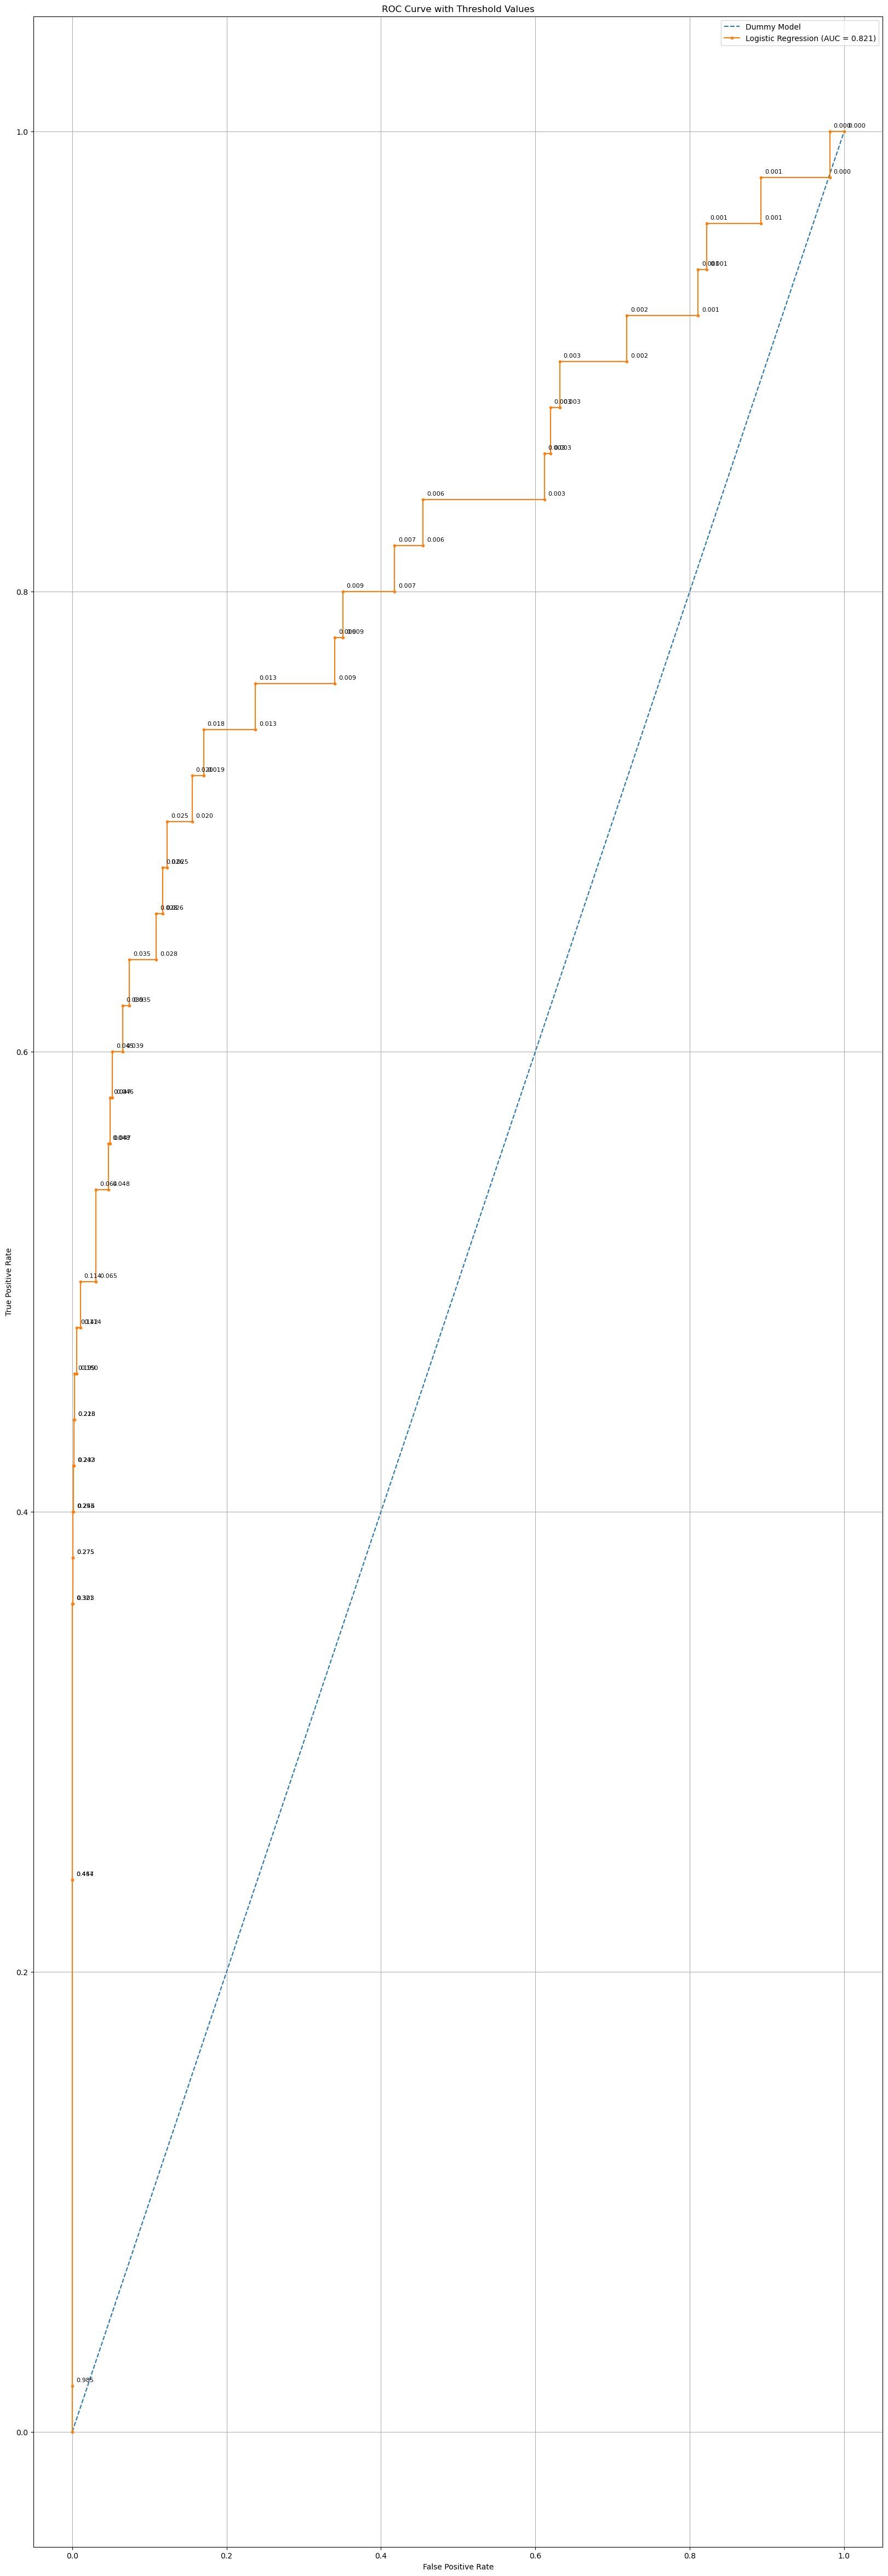

In [127]:
fig, ax = plt.subplots(figsize=(20,60))
ax.plot(dummy_fpr, dummy_tpr,linestyle='--',label='Dummy Model')
ax.plot(model_fpr,model_tpr,marker='.',label=f'Logistic Regression (AUC = {og_model_prob:.3f})')
for fpr, tpr, threshold in zip(model_fpr,model_tpr,thresholds):

    # Ignore infinity threshold
    if np.isinf(threshold):
        continue

    ax.annotate( f'{threshold:.3f}',xy=(fpr, tpr),xytext=(5, 5),textcoords='offset points',fontsize=8)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve with Threshold Values')
ax.legend()
ax.grid(True)
plt.show()